# Entrega 2 — Detecção de Duplicatas
### Desafio 1 · Ouvidoria Inteligente: Triagem Semântica de Manifestações Cidadãs

Processamento de Linguagem Natural / Engenharia de IA · Anna Maria

Construção da função `detectar_duplicatas(textos, limiar=0.85)`, que recebe as manifestações e devolve
todos os pares com similaridade de cosseno (sobre embeddings) acima do limiar. O notebook apresenta:

1. a matriz de similaridade completa (heatmap);
2. a lista de pares duplicados encontrados;
3. a justificativa do limiar, com base na distribuição de similaridades do corpus;
4. a análise de falsos positivos e falsos negativos contra as duplicatas reais do dataset.

Os modelos e o pré-processamento seguem a Entrega 1 (`análise_comparativa.ipynb`) para que os
resultados sejam comparáveis.

## 1. Configuração e Carga dos Dados

In [1]:
!pip install -q sentence-transformers scikit-learn pandas numpy matplotlib seaborn

In [2]:
import json
import os

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110

In [3]:
CAMINHO_JSON = "manifestacoes.json"

# Mesmos modelos da Entrega 1 (BAAI/bge-small-pt-v1.5 não existe publicamente no Hugging Face)
MODELOS = {
    "MiniLM-L12": "paraphrase-multilingual-MiniLM-L12-v2",
    "DistilUSE": "distiluse-base-multilingual-cased-v2",
}
MODELO_PRINCIPAL = "MiniLM-L12"   # maior margem relevante x controle na Entrega 1

LIMIAR_PADRAO = 0.85              # valor sugerido pelo enunciado

# Gabarito: duplicatas semânticas reais do dataset (~15% das 40 manifestações = 6 textos = 3 pares)
DUPLICATAS_REAIS = {("M003", "M017"), ("M008", "M022"), ("M006", "M028")}

In [4]:
# Upload do dataset quando executado no Colab
try:
    import google.colab
    from google.colab import files
    if not os.path.exists(CAMINHO_JSON):
        files.upload()
except ImportError:
    pass

In [5]:
with open(CAMINHO_JSON, encoding="utf-8") as f:
    dados = json.load(f)
if isinstance(dados, dict):
    dados = next(v for v in dados.values() if isinstance(v, list))

df = pd.DataFrame(dados)
assert {"id", "texto", "categoria_oficial"} <= set(df.columns)
assert df["id"].is_unique
assert {i for par in DUPLICATAS_REAIS for i in par} <= set(df["id"])

textos = df["texto"].tolist()
ids = df["id"].tolist()
posicao = {id_: k for k, id_ in enumerate(ids)}
categoria = dict(zip(df["id"], df["categoria_oficial"]))
texto_de = dict(zip(df["id"], df["texto"]))

n = len(df)
print(f"{n} manifestações | {n * (n - 1) // 2} pares possíveis | {len(DUPLICATAS_REAIS)} duplicatas reais")

40 manifestações | 780 pares possíveis | 3 duplicatas reais


## 2. Gabarito: Duplicatas Reais do Dataset

In [6]:
display(pd.DataFrame([
    {"Par": f"{a} × {b}", "categoria": categoria[a], "texto 1": texto_de[a], "texto 2": texto_de[b]}
    for a, b in sorted(DUPLICATAS_REAIS)
]).set_index("Par"))

,categoria,texto 1,texto 2
Par,,,
M003 × M017,infraestrutura,"Buraco enorme na Av. Brasil, já causou dois acidentes com motos esta semana.","Asfalto todo esburacado da avenida principal, carros danificados."
M006 × M028,meio ambiente,"Lixo acumulado há semanas em terreno baldio na Rua Acácia, atraindo ratos e insetos, moradores temem doenças.",Descarte irregular de lixo em terreno baldio na Rua Acácia atrai insetos e provoca mau cheiro na vizinhança.
M008 × M022,saúde,"Posto de saúde sem médico há duas semanas, ninguém é atendido.","Falta atendimento no PSF do meu bairro, sem médico e sem enfermeira."


Os três pares têm perfis bem diferentes, o que torna o gabarito um bom teste:

- **M006 × M028** — mesmo local (Rua Acácia) e vocabulário parcialmente compartilhado ("lixo", "terreno baldio", "insetos");
- **M008 × M022** — mesmo problema com poucas palavras em comum ("médico", "sem") e a sigla "PSF" no lugar de "posto de saúde";
- **M003 × M017** — mesmo problema **sem nenhuma palavra em comum** ("buraco"/"esburacado", "Av. Brasil"/"avenida principal").

## 3. Embeddings

Os embeddings são normalizados (`normalize_embeddings=True`), de modo que a matriz de similaridade
é simplesmente `E @ E.T`.

In [7]:
from sentence_transformers import SentenceTransformer

modelos, embeddings = {}, {}
for rotulo, nome_modelo in MODELOS.items():
    try:
        modelos[rotulo] = SentenceTransformer(nome_modelo)
        embeddings[rotulo] = modelos[rotulo].encode(textos, normalize_embeddings=True, show_progress_bar=False)
        print(f"✔ {rotulo} ({nome_modelo}) -> {embeddings[rotulo].shape}")
    except Exception as erro:
        print(f"⚠ Falha ao carregar {rotulo} ({nome_modelo}): {erro}")

assert MODELO_PRINCIPAL in embeddings, "O modelo principal não foi carregado."

/home/milena/Documentos/agroSearch/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2626.81it/s]


✔ MiniLM-L12 (paraphrase-multilingual-MiniLM-L12-v2) -> (40, 384)


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2416.55it/s]


✔ DistilUSE (distiluse-base-multilingual-cased-v2) -> (40, 512)


## 4. Função `detectar_duplicatas`

A função aceita o limiar de duas formas:

- **valor fixo** de cosseno (ex.: `0.85`, o padrão do enunciado);
- **limiar dinâmico** por percentil, como `"p99"`: o corte passa a ser o percentil 99 da distribuição
  de similaridades de todos os pares do próprio corpus. Isso adapta o limiar à linha de base de cada
  modelo (na Entrega 1, a similaridade média entre pares aleatórios já era 0,17–0,23).

In [8]:
def matriz_similaridade(textos, modelo):
    """Matriz n x n de similaridade de cosseno entre os embeddings dos textos."""
    E = modelo.encode(textos, normalize_embeddings=True, show_progress_bar=False)
    return E @ E.T


def similaridades_dos_pares(S):
    """Valores do triângulo superior (i < j): uma similaridade por par distinto."""
    return S[np.triu_indices_from(S, k=1)]


def resolver_limiar(S, limiar):
    """Converte o limiar em valor de cosseno. Aceita float (0.85) ou percentil em texto ("p99")."""
    if isinstance(limiar, str):
        p = float(limiar.lower().lstrip("p"))
        return float(np.percentile(similaridades_dos_pares(S), p))
    return float(limiar)


def detectar_duplicatas(textos, limiar=0.85, modelo=None, ids=None, S=None):
    """
    Retorna todos os pares de manifestações com similaridade de cosseno acima do limiar.

    Parâmetros
    ----------
    textos : list[str]  lista de manifestações
    limiar : float | str  corte de cosseno (ex. 0.85) ou percentil do corpus (ex. "p99")
    modelo : SentenceTransformer  modelo de embedding (padrão: MODELO_PRINCIPAL)
    ids    : list[str]  identificadores dos textos (padrão: posição na lista)
    S      : np.ndarray  matriz de similaridade já calculada (evita recodificar os textos)

    Retorno
    -------
    DataFrame com colunas id_a, id_b, similaridade, ordenado da maior para a menor similaridade.
    O limiar efetivamente aplicado fica em `resultado.attrs["limiar"]`.
    """
    if S is None:
        S = matriz_similaridade(textos, modelo or modelos[MODELO_PRINCIPAL])
    ids = ids if ids is not None else [str(k) for k in range(len(textos))]
    corte = resolver_limiar(S, limiar)

    i, j = np.triu_indices_from(S, k=1)
    acima = S[i, j] > corte
    resultado = pd.DataFrame({
        "id_a": np.array(ids)[i[acima]],
        "id_b": np.array(ids)[j[acima]],
        "similaridade": S[i, j][acima],
    }).sort_values("similaridade", ascending=False, ignore_index=True)
    resultado.attrs["limiar"] = corte
    return resultado

In [9]:
# Matrizes de similaridade de cada modelo (calculadas uma vez e reaproveitadas)
matrizes = {rotulo: E @ E.T for rotulo, E in embeddings.items()}

# Linha de base lexical (TF-IDF da Entrega 1), usada apenas como comparação
STOPWORDS_PT = sorted({w for w in '''
    as os um uma uns umas de do da dos das em no na nos nas num numa por pelo pela pelos pelas para pra
    com sobre entre ate ao aos ou mas que se como ja tambem mais menos muito muitos pouco so ainda entao
    porque pois quando onde qual quais quem eu tu ele ela eles elas voce me te lhe lhes meu minha teu tua
    seu sua seus suas nosso nossa este esta esse essa isto isso aquele aquela aquilo ser sao foi era sido
    ter tem tinha ha estar estao durante apos antes desde depois cada todo toda todos todas outro outra
    outros outras mesmo mesma la aqui ali
'''.split() if len(w) > 1})
vec_tfidf = TfidfVectorizer(lowercase=True, strip_accents="unicode", stop_words=STOPWORDS_PT)
matrizes_comparacao = dict(matrizes)
matrizes_comparacao["TF-IDF"] = cosine_similarity(vec_tfidf.fit_transform(textos))

### 4.1 Aplicando o limiar padrão do enunciado (0,85)

In [10]:
for rotulo in matrizes:
    pares = detectar_duplicatas(textos, limiar=LIMIAR_PADRAO, ids=ids, S=matrizes[rotulo])
    maximo = similaridades_dos_pares(matrizes[rotulo]).max()
    print(f"{rotulo:>11}: {len(pares)} par(es) acima de {LIMIAR_PADRAO} | maior similaridade do corpus = {maximo:.4f}")
    if len(pares):
        display(pares)

 MiniLM-L12: 0 par(es) acima de 0.85 | maior similaridade do corpus = 0.8351
  DistilUSE: 0 par(es) acima de 0.85 | maior similaridade do corpus = 0.6942


## 5. Matriz de Similaridade Completa (Heatmap)

As manifestações estão ordenadas por categoria oficial, de modo que blocos mais claros na diagonal
indicam temas coesos. Os quadrados **verdes** marcam as duplicatas reais do gabarito. A diagonal
(cada texto consigo mesmo, cosseno = 1) fica em branco para não achatar a escala de cores.

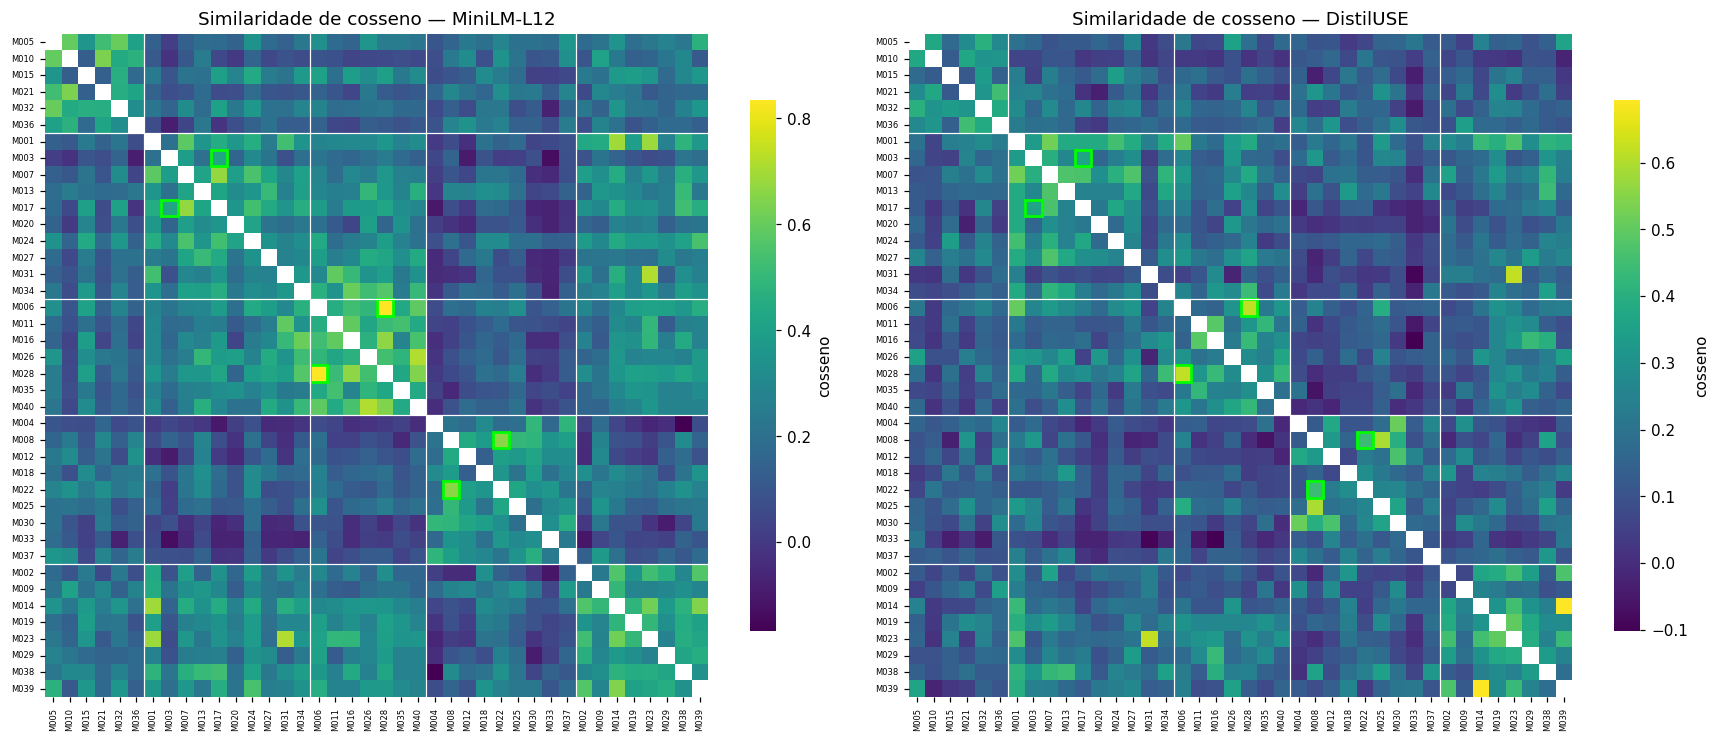

educação: 6 | infraestrutura: 10 | meio ambiente: 7 | saúde: 9 | segurança: 8


In [11]:
ordem = df.sort_values(["categoria_oficial", "id"])["id"].tolist()
idx_ordem = [posicao[i] for i in ordem]
fronteiras = np.cumsum(df.set_index("id").loc[ordem, "categoria_oficial"].value_counts(sort=False).values)

def heatmap(S, titulo, ax):
    S_ord = S[np.ix_(idx_ordem, idx_ordem)].astype(float).copy()
    np.fill_diagonal(S_ord, np.nan)   # diagonal (=1) oculta para não achatar a escala de cores
    sns.heatmap(S_ord, ax=ax, cmap="viridis", vmin=min(0, np.nanmin(S_ord)), vmax=np.nanmax(S_ord), square=True,
                xticklabels=ordem, yticklabels=ordem, cbar_kws={"shrink": 0.7, "label": "cosseno"})
    ax.tick_params(labelsize=5.5)
    for f in fronteiras[:-1]:
        ax.axhline(f, color="white", lw=0.8)
        ax.axvline(f, color="white", lw=0.8)
    for a, b in DUPLICATAS_REAIS:
        for r, c in ((ordem.index(a), ordem.index(b)), (ordem.index(b), ordem.index(a))):
            ax.add_patch(patches.Rectangle((c, r), 1, 1, fill=False, edgecolor="lime", lw=1.8))
    ax.set_title(titulo)

fig, axes = plt.subplots(1, len(matrizes), figsize=(8 * len(matrizes), 7.2))
for ax, (rotulo, S) in zip(np.atleast_1d(axes), matrizes.items()):
    heatmap(S, f"Similaridade de cosseno — {rotulo}", ax)
plt.tight_layout()
plt.show()

# Legenda das faixas de categoria (na ordem do heatmap)
print(" | ".join(f"{c}: {q}" for c, q in df["categoria_oficial"].value_counts().sort_index().items()))

## 6. Escolha do Limiar

### 6.1 Distribuição das similaridades e posição das duplicatas reais

Um limiar só faz sentido em relação à distribuição de similaridades do corpus: a mesma similaridade de
0,6 pode ser alta para um modelo e comum para outro.

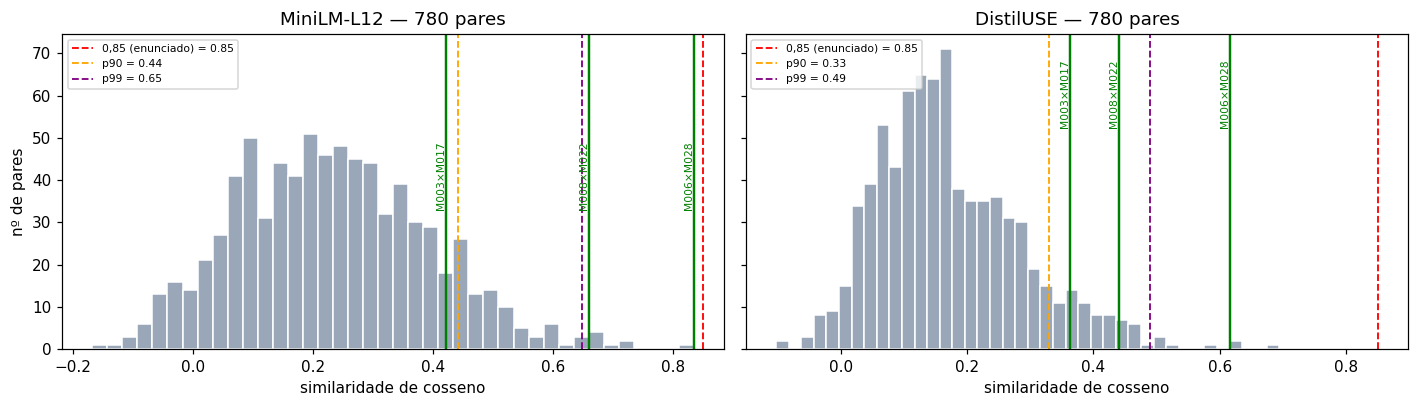

In [12]:
fig, axes = plt.subplots(1, len(matrizes), figsize=(6.5 * len(matrizes), 3.8), sharey=True)
for ax, (rotulo, S) in zip(np.atleast_1d(axes), matrizes.items()):
    todos = similaridades_dos_pares(S)
    ax.hist(todos, bins=40, color="#9aa7b8", edgecolor="white")
    for rot, v, cor in [("0,85 (enunciado)", LIMIAR_PADRAO, "red"),
                        ("p90", np.percentile(todos, 90), "orange"),
                        ("p99", np.percentile(todos, 99), "purple")]:
        ax.axvline(v, color=cor, ls="--", lw=1.2, label=f"{rot} = {v:.2f}")
    for a, b in sorted(DUPLICATAS_REAIS):
        v = S[posicao[a], posicao[b]]
        ax.axvline(v, color="green", lw=1.6)
        ax.text(v, ax.get_ylim()[1] * 0.92, f"{a}×{b}", rotation=90, fontsize=7, ha="right", va="top", color="green")
    ax.set_title(f"{rotulo} — {len(todos)} pares")
    ax.set_xlabel("similaridade de cosseno")
    ax.legend(fontsize=7, loc="upper left")
axes[0].set_ylabel("nº de pares")
plt.tight_layout()
plt.show()

In [13]:
# Posição (rank) de cada duplicata real no ranking dos 780 pares, do mais para o menos similar
def ranking_dos_pares(S):
    i, j = np.triu_indices_from(S, k=1)
    r = pd.DataFrame({"id_a": np.array(ids)[i], "id_b": np.array(ids)[j], "similaridade": S[i, j]})
    r = r.sort_values("similaridade", ascending=False, ignore_index=True)
    r["rank"] = np.arange(1, len(r) + 1)
    return r

linhas = []
for rotulo, S in matrizes_comparacao.items():
    r = ranking_dos_pares(S).set_index(["id_a", "id_b"])
    for a, b in sorted(DUPLICATAS_REAIS):
        linhas.append({"Representação": rotulo, "Par": f"{a} × {b}",
                       "similaridade": r.loc[(a, b), "similaridade"], "rank (de 780)": r.loc[(a, b), "rank"]})
tab_rank = pd.DataFrame(linhas).pivot(index="Par", columns="Representação")
display(tab_rank)

similaridade                    rank (de 780)                  
Representação    DistilUSE MiniLM-L12  TF-IDF     DistilUSE MiniLM-L12 TF-IDF
Par                                                                          
M003 × M017         0.3628     0.4217  0.0000            59         92    355
M006 × M028         0.6165     0.8351  0.4183             3          1      1
M008 × M022         0.4400     0.6608  0.2596            21          8      3

### 6.2 Varredura do limiar: precisão, revocação e F1

Para cada limiar possível, os pares detectados são comparados com o gabarito:

- **VP** — par detectado que é duplicata real; **FP** — par detectado que não é; **FN** — duplicata real não detectada;
- **precisão** = VP / (VP + FP); **revocação** = VP / (VP + FN); **F1** = média harmônica das duas.

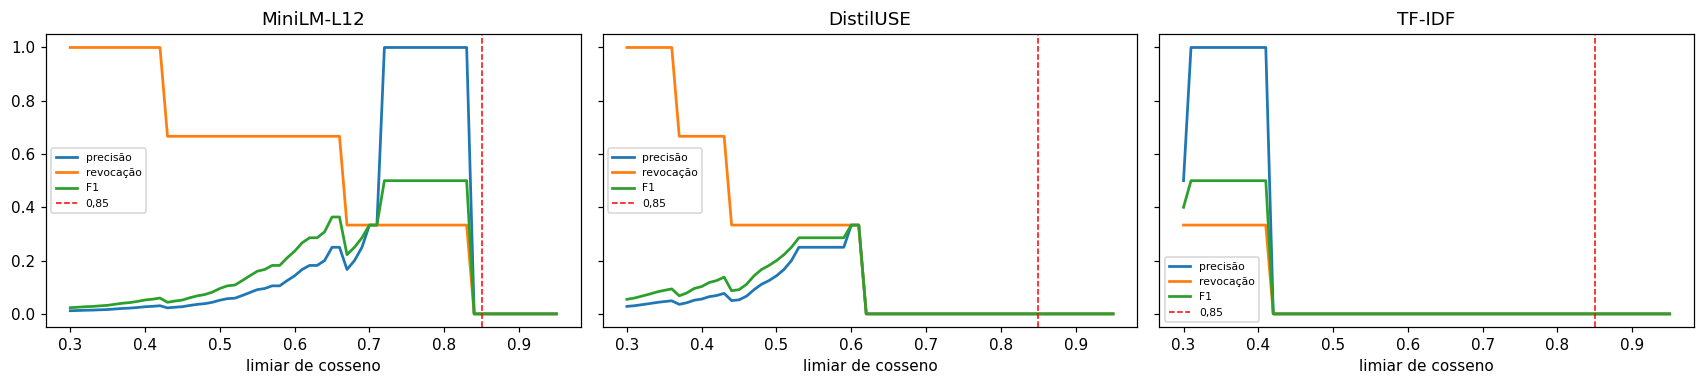

In [14]:
def avaliar(pares_detectados, gabarito=DUPLICATAS_REAIS):
    detectados = {tuple(sorted(p)) for p in zip(pares_detectados["id_a"], pares_detectados["id_b"])}
    gabarito = {tuple(sorted(p)) for p in gabarito}
    vp, fp, fn = len(detectados & gabarito), len(detectados - gabarito), len(gabarito - detectados)
    precisao = vp / (vp + fp) if vp + fp else 0.0
    revocacao = vp / (vp + fn)
    f1 = 2 * precisao * revocacao / (precisao + revocacao) if precisao + revocacao else 0.0
    return {"detectados": vp + fp, "VP": vp, "FP": fp, "FN": fn,
            "precisão": precisao, "revocação": revocacao, "F1": f1}

varreduras = {}
for rotulo, S in matrizes_comparacao.items():
    grade = np.round(np.arange(0.30, 0.951, 0.01), 2)
    varreduras[rotulo] = pd.DataFrame(
        [{"limiar": t, **avaliar(detectar_duplicatas(textos, t, ids=ids, S=S))} for t in grade]
    ).set_index("limiar")

fig, axes = plt.subplots(1, len(varreduras), figsize=(5.2 * len(varreduras), 3.6), sharey=True)
for ax, (rotulo, v) in zip(np.atleast_1d(axes), varreduras.items()):
    v[["precisão", "revocação", "F1"]].plot(ax=ax, lw=1.8)
    ax.axvline(LIMIAR_PADRAO, color="red", ls="--", lw=1, label="0,85")
    ax.set_title(rotulo)
    ax.set_xlabel("limiar de cosseno")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [15]:
# Melhor limiar por F1 em cada representação (em caso de empate, o maior limiar = mais conservador)
melhores = []
for rotulo, v in varreduras.items():
    melhor_f1 = v["F1"].max()
    t = v.index[v["F1"] == melhor_f1].max()
    melhores.append({"Representação": rotulo, "limiar ótimo (F1)": t, **v.loc[t].to_dict()})
display(pd.DataFrame(melhores).set_index("Representação"))

# Limiares dinâmicos por percentil (dica do enunciado) no modelo principal
S = matrizes[MODELO_PRINCIPAL]
linhas = []
for lim in [LIMIAR_PADRAO, "p90", "p95", "p98", "p99", "p99.5"]:
    pares = detectar_duplicatas(textos, lim, ids=ids, S=S)
    linhas.append({"limiar": str(lim), "cosseno equivalente": pares.attrs["limiar"], **avaliar(pares)})
print(f"Limiares fixo x dinâmico — {MODELO_PRINCIPAL}")
display(pd.DataFrame(linhas).set_index("limiar"))

,limiar ótimo (F1),detectados,VP,FP,FN,precisão,revocação,F1
Representação,,,,,,,,
MiniLM-L12,0.83,1.0,1.0,0.0,2.0,1.0000,0.3333,0.5000
DistilUSE,0.61,3.0,1.0,2.0,2.0,0.3333,0.3333,0.3333
TF-IDF,0.41,1.0,1.0,0.0,2.0,1.0000,0.3333,0.5000


Limiares fixo x dinâmico — MiniLM-L12


,cosseno equivalente,detectados,VP,FP,FN,precisão,revocação,F1
limiar,,,,,,,,
0.85,0.8500,0,0,0,3,0.0000,0.0000,0.0000
p90,0.4416,78,2,76,1,0.0256,0.6667,0.0494
p95,0.4975,39,2,37,1,0.0513,0.6667,0.0952
p98,0.5906,16,2,14,1,0.1250,0.6667,0.2105
p99,0.6490,8,2,6,1,0.2500,0.6667,0.3636
p99.5,0.6836,4,1,3,2,0.2500,0.3333,0.2857


### 6.3 Limiar adotado

*(a justificativa final é escrita após a execução com os modelos reais — ver Seção 8)*

In [16]:
# Limiar escolhido para o modelo principal (ajustado após a análise da Seção 6)
LIMIAR_ESCOLHIDO = float(pd.DataFrame(melhores).set_index("Representação").loc[MODELO_PRINCIPAL, "limiar ótimo (F1)"])
print(f"Limiar adotado ({MODELO_PRINCIPAL}): {LIMIAR_ESCOLHIDO:.2f}")

Limiar adotado (MiniLM-L12): 0.83


## 7. Pares Duplicados Encontrados

In [17]:
GABARITO_NORM = {tuple(sorted(p)) for p in DUPLICATAS_REAIS}

def detalhar(pares):
    out = pares.copy()
    out["situação"] = ["✅ VP" if tuple(sorted((a, b))) in GABARITO_NORM else "❌ FP"
                       for a, b in zip(out["id_a"], out["id_b"])]
    out["categorias"] = [f"{categoria[a]} / {categoria[b]}" for a, b in zip(out["id_a"], out["id_b"])]
    out["texto A"] = out["id_a"].map(texto_de)
    out["texto B"] = out["id_b"].map(texto_de)
    return out

encontrados = detectar_duplicatas(textos, LIMIAR_ESCOLHIDO, ids=ids, S=matrizes[MODELO_PRINCIPAL])
print(f"{MODELO_PRINCIPAL} | limiar {encontrados.attrs['limiar']:.2f} | {len(encontrados)} par(es) detectado(s)")
display(detalhar(encontrados))

MiniLM-L12 | limiar 0.83 | 1 par(es) detectado(s)


,id_a,id_b,similaridade,situação,categorias,texto A,texto B
0,M006,M028,0.8351,✅ VP,meio ambiente / meio ambiente,"Lixo acumulado há semanas em terreno baldio na Rua Acácia, atraindo ratos e insetos, moradores temem doenças.",Descarte irregular de lixo em terreno baldio na Rua Acácia atrai insetos e provoca mau cheiro na vizinhança.


## 8. Análise de Falsos Positivos e Falsos Negativos

Para enxergar além do limiar escolhido, a análise olha os **15 pares mais similares** do corpus
(candidatos a falso positivo) e todas as duplicatas reais que ficaram abaixo do corte (falsos negativos).

In [18]:
analisador = vec_tfidf.build_analyzer()
def termos_em_comum(a, b):
    return sorted(set(analisador(texto_de[a])) & set(analisador(texto_de[b])))

top = detalhar(ranking_dos_pares(matrizes[MODELO_PRINCIPAL]).head(15))
top["mesma categoria"] = [categoria[a] == categoria[b] for a, b in zip(top["id_a"], top["id_b"])]
top["termos em comum"] = [", ".join(termos_em_comum(a, b)) or "—" for a, b in zip(top["id_a"], top["id_b"])]
top["acima do limiar"] = top["similaridade"] > LIMIAR_ESCOLHIDO
display(top[["rank", "id_a", "id_b", "similaridade", "situação", "acima do limiar",
             "categorias", "mesma categoria", "termos em comum", "texto A", "texto B"]])

,rank,id_a,id_b,similaridade,situação,acima do limiar,categorias,mesma categoria,termos em comum,texto A,texto B
0,1,M006,M028,0.8351,✅ VP,True,meio ambiente / meio ambiente,True,"acacia, baldio, insetos, lixo, rua, terreno","Lixo acumulado há semanas em terreno baldio na Rua Acácia, atraindo ratos e insetos, moradores temem doenças.",Descarte irregular de lixo em terreno baldio na Rua Acácia atrai insetos e provoca mau cheiro na vizinhança.
1,2,M026,M040,0.7172,❌ FP,False,meio ambiente / meio ambiente,True,"agua, cheiro, moradores","O rio que corta o bairro Porto Alegre do Sul vem apresentando uma coloração esverdeada e cheiro forte nas últimas três semanas, o que moradores associam ao despejo de resíduos por uma fábrica têxt...","Poço de água usado pela comunidade rural está contaminado, moradores relatam mau cheiro e cor escura na água."
2,3,M023,M031,0.7151,❌ FP,False,segurança / infraestrutura,False,"noite, praca","Iluminação apagada na praça do bairro favorece assaltos à noite, moradores relatam medo de sair de casa.",Lâmpada queimada na praça deixa o local escuro à noite.
3,4,M001,M014,0.6936,❌ FP,False,infraestrutura / segurança,False,rua,"Poste de luz caído na calçada da Rua dos Girassóis há mais de uma semana, oferecendo risco aos pedestres que passam pelo local.","Nos últimos dois meses, o bairro Vila Esperança registrou pelo menos seis assaltos a mão armada, sempre no mesmo trecho da Rua das Oliveiras, entre as 19h e as 21h. Os moradores relatam que a ilum..."
4,5,M001,M023,0.6824,❌ FP,False,infraestrutura / segurança,False,—,"Poste de luz caído na calçada da Rua dos Girassóis há mais de uma semana, oferecendo risco aos pedestres que passam pelo local.","Iluminação apagada na praça do bairro favorece assaltos à noite, moradores relatam medo de sair de casa."
5,6,M007,M017,0.6739,❌ FP,False,infraestrutura / infraestrutura,True,—,Sinal de trânsito quebrado no cruzamento da Rua Prado com Av. Central causa engarrafamentos diários.,"Asfalto todo esburacado da avenida principal, carros danificados."
6,7,M016,M028,0.6641,❌ FP,False,meio ambiente / meio ambiente,True,"cheiro, vizinhanca","Fábrica na zona industrial libera fumaça com cheiro forte durante a madrugada, incomodando toda a vizinhança.",Descarte irregular de lixo em terreno baldio na Rua Acácia atrai insetos e provoca mau cheiro na vizinhança.
7,8,M008,M022,0.6608,✅ VP,False,saúde / saúde,True,"medico, sem","Posto de saúde sem médico há duas semanas, ninguém é atendido.","Falta atendimento no PSF do meu bairro, sem médico e sem enfermeira."
8,9,M014,M039,0.6458,❌ FP,False,segurança / segurança,True,"associacao, bairro, caminhar, esperanca, meses, moradores, noite, onibus, ponto, publica, regiao, reuniao, rondas, secretaria, seguranca, tres, ultimos","Nos últimos dois meses, o bairro Vila Esperança registrou pelo menos seis assaltos a mão armada, sempre no mesmo trecho da Rua das Oliveiras, entre as 19h e as 21h. Os moradores relatam que a ilum...","Na última reunião da associação de moradores do bairro Nova Esperança, o clima foi de indignação. Nos últimos três meses, os casos de violência aumentaram consideravelmente: houve duas tentativas ..."
9,10,M028,M040,0.6442,❌ FP,False,meio ambiente / meio ambiente,True,"cheiro, mau",Descarte irregular de lixo em terreno baldio na Rua Acácia atrai insetos e provoca mau cheiro na vizinhança.,"Poço de água usado pela comunidade rural está contaminado, moradores relatam mau cheiro e cor escura na água."


In [19]:
# Falsos negativos: duplicatas reais abaixo do limiar escolhido
r = ranking_dos_pares(matrizes[MODELO_PRINCIPAL]).set_index(["id_a", "id_b"])
fn = [{"Par": f"{a} × {b}", "similaridade": r.loc[(a, b), "similaridade"], "rank": r.loc[(a, b), "rank"],
       "pares à frente que não são duplicatas": int(r.loc[(a, b), "rank"]) - 1
           - sum(r.loc[p, "rank"] < r.loc[(a, b), "rank"] for p in GABARITO_NORM if p != (a, b)),
       "termos em comum": ", ".join(termos_em_comum(a, b)) or "—"}
      for a, b in sorted(GABARITO_NORM) if r.loc[(a, b), "similaridade"] <= LIMIAR_ESCOLHIDO]
display(pd.DataFrame(fn).set_index("Par") if fn else "Nenhum falso negativo no limiar escolhido.")

,similaridade,rank,pares à frente que não são duplicatas,termos em comum
Par,,,,
M003 × M017,0.4217,92,89,—
M008 × M022,0.6608,8,6,"medico, sem"


### 8.1 Discussão

*(escrita após a execução com os modelos reais)*

## 9. Conclusão

*(escrita após a execução com os modelos reais)*